# 02 · Coming from batman

**Level:** beginner · **Prerequisites:** [01](01_first_light_curve.ipynb); some batman experience helps · **Run time:** ~1 min

**Covers:** `import pizzetti as batman`, supported batman features and options, accuracy and speed against batman, identical emcee chains

pizzetti accepts the same objects and calls as batman. This notebook shows what carries over unchanged, what differs, and what you gain.

In [1]:
import os, time
import numpy as np
import matplotlib.pyplot as plt
import emcee
import batman
import pizzetti

SMOKE = os.environ.get("PIZZETTI_SMOKE") == "1"      # shorter runs in the automatic tests
print("batman", batman.__version__, "| pizzetti", pizzetti.__version__)

batman 2.5.1 | pizzetti 0.3.0


## 1. The one-line switch

Code written for batman runs with pizzetti after `import pizzetti as batman`. Here both packages
compute the same light curve from the same script.

In [2]:
def light_curve(module, law="quadratic", u=(0.4, 0.25), t=np.linspace(-0.12, 0.12, 4001)):
    p = module.TransitParams()
    p.t0, p.per, p.rp, p.a, p.inc, p.ecc, p.w = 0.0, 3.5, 0.1, 9.0, 87.7, 0.0, 90.0
    p.limb_dark, p.u = law, list(u)
    return module.TransitModel(p, t).light_curve(p)

fb, fp = light_curve(batman), light_curve(pizzetti)
print(f"largest difference batman - pizzetti (quadratic law): {np.max(np.abs(fb - fp)):.1e}")

largest difference batman - pizzetti (quadratic law): 6.4e-09


## 2. What carries over

| batman feature | pizzetti |
|---|---|
| `TransitParams` attributes (`t0, per, rp, a, inc, ecc, w, u, limb_dark, fp, t_secondary`) | same |
| `TransitModel(params, t, supersample_factor=, exp_time=, transittype=)` | same |
| `light_curve`, `get_t_secondary`, `get_t_periastron`, `get_t_conjunction`, `get_true_anomaly`, `calc_err` | same |
| laws `uniform, linear, quadratic, squareroot, nonlinear, power2` | same |
| laws `logarithmic, exponential, custom` | not sums of powers of μ: `NotImplementedError` (logarithmic: see `MarginalTransitModel`, notebook 06) |
| `max_err`, `fac`, `nthreads` | accepted and ignored: pizzetti's error control is not a step size |

pizzetti adds two keywords: `series_tol` (the proven bound of the interior series, default 10⁻⁹) and
`limb` (the method at the limb; notebook 07).

In [3]:
try:
    light_curve(pizzetti, law="exponential", u=(0.5,))
except NotImplementedError as err:
    print("NotImplementedError:", err)

NotImplementedError: "exponential" limb darkening is not a sum of powers of mu and is not supported by pizzetti; supported: uniform, linear, quadratic, squareroot, nonlinear, power2


## 3. Accuracy

For the quadratic law both codes use closed forms and agree to ~10⁻⁹. For the other laws batman
integrates the stellar disk numerically to a tolerance `max_err` (default 1 ppm), while pizzetti stays
at the level of rounding. The reference below is pizzetti's Green's-theorem quadrature with the series
switched off (accurate to ~10⁻¹⁶; it is checked against 40-digit arithmetic in the test suite).

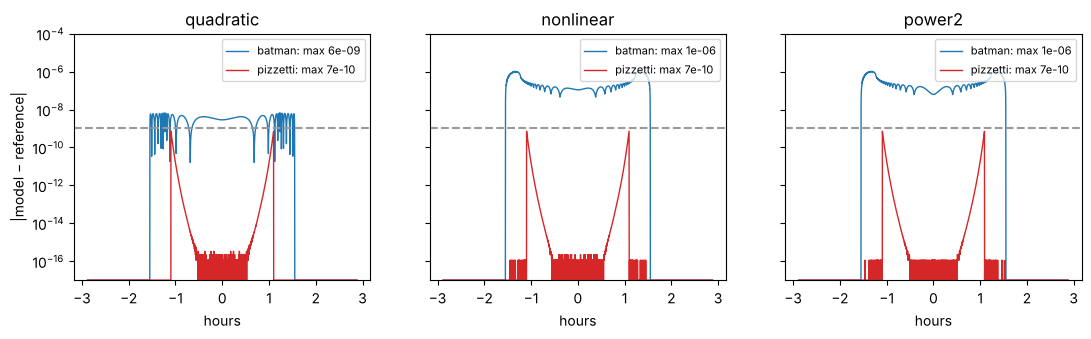

In [4]:
t = np.linspace(-0.12, 0.12, 4001)
p = pizzetti.TransitParams()
p.t0, p.per, p.rp, p.a, p.inc, p.ecc, p.w = 0.0, 3.5, 0.1, 9.0, 87.7, 0.0, 90.0
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2), sharey=True)
for ax, (law, u) in zip(axes, [("quadratic", [0.4, 0.25]), ("nonlinear", [0.5, 0.1, 0.1, -0.1]), ("power2", [0.7, 0.6])]):
    p.limb_dark, p.u = law, u
    ref = pizzetti.TransitModel(p, t, series_tol=0.0, limb="quadrature").light_curve(p)
    for name, f, col in (("batman", light_curve(batman, law, u, t), "C0"), ("pizzetti", light_curve(pizzetti, law, u, t), "C3")):
        e = np.abs(f - ref)
        ax.semilogy(24 * t, np.maximum(e, 1e-17), color=col, lw=1, label=f"{name}: max {e.max():.0e}")
    ax.axhline(1e-9, ls="--", color="0.6")
    ax.set(title=law, xlabel="hours", ylim=(1e-17, 1e-4)); ax.legend(fontsize=8, loc="upper right")
axes[0].set_ylabel("|model − reference|");

## 4. Speed

The cost of one light curve (orbit included), for 10⁵ points of which ~35 % are in transit:

In [5]:
def best(f, repeat=5):
    f(); ts = []
    for _ in range(repeat):
        s = time.perf_counter(); f(); ts.append(time.perf_counter() - s)
    return min(ts)

t5 = np.linspace(-0.25, 0.25, 100_000)
print(f"{'law':10s} {'batman [ms]':>12s} {'pizzetti [ms]':>14s} {'speed-up':>9s}")
for law, u in [("quadratic", [0.4, 0.25]), ("nonlinear", [0.5, 0.1, 0.1, -0.1]), ("power2", [0.7, 0.6])]:
    tm = {}
    for mod in (batman, pizzetti):
        q = mod.TransitParams()
        q.t0, q.per, q.rp, q.a, q.inc, q.ecc, q.w, q.limb_dark, q.u = 0.0, 10.0, 0.1, 20.0, 89.5, 0.0, 90.0, law, u
        m = mod.TransitModel(q, t5)
        tm[mod.__name__] = best(lambda: m.light_curve(q))
    print(f"{law:10s} {1e3 * tm['batman']:12.3f} {1e3 * tm['pizzetti']:14.3f} {tm['batman'] / tm['pizzetti']:8.1f}x")

law         batman [ms]  pizzetti [ms]  speed-up
quadratic         2.044          0.257      7.9x
nonlinear        38.060          0.663     57.4x
power2           24.281          0.528     46.0x


## 5. The same fit with both codes

An emcee fit of a synthetic TESS-like hot Jupiter, once with each code, with the same likelihood,
starting positions and random numbers. Because the models differ by less than 10⁻⁸, the two chains
are identical step by step until a tiny difference flips one accept/reject decision; after that they
remain statistically identical.

In [6]:
truth = dict(t0=0.0, per=3.5, rp=0.10, a=9.0, b=0.35, u1=0.40, u2=0.25)
sigma = 500e-6
t = (np.arange(7)[:, None] * truth["per"] + np.arange(-0.13, 0.13, 2.0 / 1440)[None, :]).ravel()

def make_params(module, t0, per, rp, a, b, u1, u2):
    q = module.TransitParams()
    q.t0, q.per, q.rp, q.a = t0, per, rp, a
    q.inc = np.degrees(np.arccos(b / a))
    q.ecc, q.w, q.limb_dark, q.u = 0.0, 90.0, "quadratic", [u1, u2]
    return q

ptrue = make_params(pizzetti, **truth)
y = pizzetti.TransitModel(ptrue, t, series_tol=0.0, limb="quadrature").light_curve(ptrue)
y = y + sigma * np.random.default_rng(42).standard_normal(t.size)

def make_log_prob(module):
    q = make_params(module, **truth)
    m = module.TransitModel(q, t)
    def log_prob(th):
        t0, per, rp, a, b, u1, u2 = th
        if not (0 < rp < 0.5 and 1.5 < a < 100 and 0 <= b < 1 + rp and 0 < u1 + u2 < 1 and u1 > 0):
            return -np.inf
        q.t0, q.per, q.rp, q.a, q.inc, q.u = t0, per, rp, a, np.degrees(np.arccos(b / a)), [u1, u2]
        r = y - m.light_curve(q)
        return -0.5 * np.dot(r, r) / sigma**2
    return log_prob

th0 = np.array(list(truth.values()))
nwalkers, nsteps = 32, (300 if SMOKE else 2000)
p0 = th0 + np.array([2e-4, 2e-6, 1e-3, 0.05, 0.02, 0.02, 0.02]) * np.random.default_rng(1).standard_normal((nwalkers, 7))
chains = {}
for module in (batman, pizzetti):
    lp = make_log_prob(module); lp(th0)
    s = emcee.EnsembleSampler(nwalkers, 7, lp)
    s.random_state = np.random.RandomState(2024).get_state()      # identical proposals
    t1 = time.perf_counter()
    s.run_mcmc(p0, nsteps, progress=False)
    chains[module.__name__] = s.get_chain()
    print(f"{module.__name__:9s} {time.perf_counter() - t1:5.1f} s")
same = np.all(chains["batman"] == chains["pizzetti"], axis=(1, 2))
print("chains identical for the first", np.argmin(same) if not same.all() else len(same), "steps")
burn = nsteps // 3
for i, n in enumerate(["t0", "per", "rp", "a", "b", "u1", "u2"]):
    xb, xp = chains["batman"][burn:, :, i].ravel(), chains["pizzetti"][burn:, :, i].ravel()
    print(f"{n:4s} batman {np.median(xb):10.6g} ± {xb.std():.1e}   pizzetti {np.median(xp):10.6g} ± {xp.std():.1e}")

batman      5.7 s


pizzetti    1.6 s
chains identical for the first 1236 steps
t0   batman -0.000152107 ± 1.1e-04   pizzetti -0.000134343 ± 1.1e-04
per  batman    3.50006 ± 3.2e-05   pizzetti    3.50005 ± 3.2e-05
rp   batman  0.0996788 ± 6.4e-04   pizzetti  0.0997196 ± 6.4e-04
a    batman    9.16781 ± 1.3e-01   pizzetti    9.15871 ± 1.3e-01
b    batman   0.298641 ± 5.5e-02   pizzetti   0.302132 ± 5.3e-02
u1   batman   0.431011 ± 4.6e-02   pizzetti   0.435078 ± 4.5e-02
u2   batman   0.201858 ± 9.4e-02   pizzetti   0.192836 ± 9.4e-02


## What you learned

- `import pizzetti as batman` is enough for existing scripts; all batman objects, methods and laws that are sums of powers of μ carry over.
- batman's `max_err`, `fac` and `nthreads` are accepted and ignored; pizzetti adds `series_tol` and `limb`.
- pizzetti's model error is ~10⁻¹⁵ for every law, against ~10⁻⁶ for batman's numerical laws.
- Fits give the same posteriors, faster.

**Next:** [03 · Your first fit](03_first_fit.ipynb)